In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import norm

In [2]:
def rsi(series, window=14):
    change = series.diff()
    gain = change.where(change > 0, 0)
    loss = -change.where(change < 0, 0)
    avg_gain = gain.rolling(window=window).mean()
    avg_loss = loss.rolling(window=window).mean()
    rs = avg_gain / avg_loss
    return 100 - (100 / (1 + rs))

In [3]:
px = yf.download('SONY', start='2020-01-01', end='2026-01-01', auto_adjust=True)['Close'].squeeze()
bill = yf.download('^IRX', start='2020-01-01', end='2026-01-01', auto_adjust=True)['Close'].squeeze() / 100

ret = px.pct_change()
rf = ((1 + bill) ** (1 / 252) - 1).reindex(ret.index).ffill()
excess = (ret - rf).dropna()

is_excess = excess[excess.index < '2023-01-01']
os_excess = excess[excess.index >= '2023-01-01']
len(is_excess), len(os_excess)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


(755, 752)

In [4]:
rng = np.random.default_rng(0)
sample_rules = pd.DataFrame({
        'window': rng.integers(2, 61, 500),
        'oversold': rng.uniform(5, 45, 500),
        'overbought': rng.uniform(55, 95, 500),
    })


def positions(ind, oversold, overbought):
    raw = pd.Series(np.nan, index=ind.index)
    raw[ind < oversold] = 1.0
    raw[ind > overbought] = 0.0
    return raw.ffill().fillna(0.0)

def sharpe(r):
    sd = r.std()
    return np.nan if sd == 0 else r.mean() / sd * np.sqrt(252)

In [5]:
def evaluate(rules, price, excess):
    """Annualized Sharpe of each rule over one return window."""
    cache = {w: rsi(price, w) for w in np.unique(rules['window'])}
    out = []
    for r in rules.itertuples():
        pos = positions(cache[r.window], r.oversold, r.overbought).shift(1)
        out.append(sharpe(pos.reindex(excess.index) * excess))
    return pd.Series(out, index=rules.index, name='sharpe')

In [6]:
in_sample = evaluate(sample_rules, px, is_excess)

best = in_sample.idxmax()
sample_rules.join(in_sample).sort_values('sharpe', ascending=False).head(10)

,window,oversold,overbought,sharpe
38,30,27.827391,72.245314,1.181328
71,20,24.379958,71.984708,1.068060
163,31,27.982266,66.846391,1.002913
377,35,19.225483,70.944245,0.975968
98,24,20.767471,74.824891,0.975962
159,29,28.455134,66.634005,0.935886
418,34,16.774550,68.683002,0.907503
79,23,18.195833,71.135662,0.902156
409,36,21.029791,58.288566,0.881266
241,22,17.128041,68.793733,0.865498


In [7]:
out_sample = evaluate(sample_rules.loc[[best]], px, os_excess)

pd.DataFrame({
    "in-sample": {"best": in_sample[best], "median": in_sample.median(), "buy and hold": sharpe(is_excess)},
    "out-of-sample": {"best": out_sample[best], "median": '-', "buy and hold": sharpe(os_excess)}
})

,in-sample,out-of-sample
best,1.181328,0.809235
median,0.280051,-
buy and hold,0.257388,0.617334


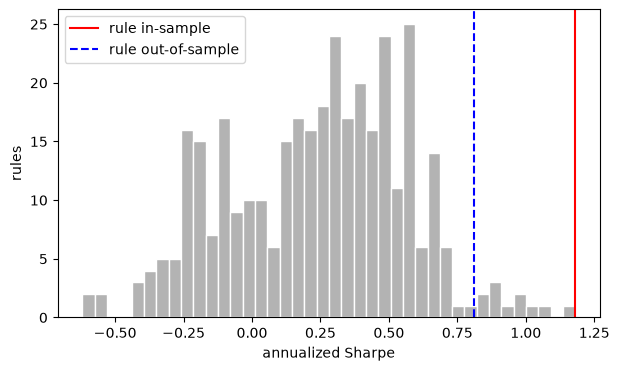

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(in_sample.dropna(), bins=40, color='0.7', edgecolor='white')
ax.axvline(in_sample[best], color='red', label='rule in-sample')
ax.axvline(out_sample[best], color='blue', ls='--', label='rule out-of-sample')
ax.set_xlabel('annualized Sharpe')
ax.set_ylabel('rules')
ax.legend()
plt.show()

In [9]:
rng_rw = np.random.default_rng(1)

rw_ret = pd.Series(rng_rw.normal(0, ret.std(), len(excess)), index=excess.index)
rw_px = (1 + rw_ret).cumprod()
rw_excess = rw_ret - rf.reindex(rw_ret.index)

rw_is_excess = rw_excess[rw_excess.index < '2023-01-01']
rw_os_excess = rw_excess[rw_excess.index >= '2023-01-01']

In [10]:
rw_in_sample = evaluate(sample_rules, rw_px, rw_is_excess)

rw_best = rw_in_sample.idxmax()
sample_rules.join(rw_in_sample).sort_values('sharpe', ascending=False).head(10)

,window,oversold,overbought,sharpe
407,13,5.375615,76.593237,0.942896
400,58,24.767968,70.360071,0.367892
175,56,26.435957,64.683776,0.347720
338,11,8.349613,73.171961,0.336256
64,53,28.535204,69.839744,0.216458
254,14,5.484057,79.071789,0.212306
355,58,28.450568,64.756411,0.133711
174,56,28.087918,58.719618,0.104268
292,57,25.322568,58.626089,0.102491
298,52,27.727693,59.391221,-0.032225


In [11]:
rw_out_sample = evaluate(sample_rules.loc[[rw_best]], rw_px, rw_os_excess)

pd.DataFrame({
    "in-sample": {"best": rw_in_sample[rw_best], "median": rw_in_sample.median(), "buy and hold": sharpe(rw_is_excess)},
    "out-of-sample": {"best": rw_out_sample[rw_best], "median": '-', "buy and hold": sharpe(rw_os_excess)}
})

,in-sample,out-of-sample
best,0.942896,NaN
median,-0.788287,-
buy and hold,-0.961656,-0.510077


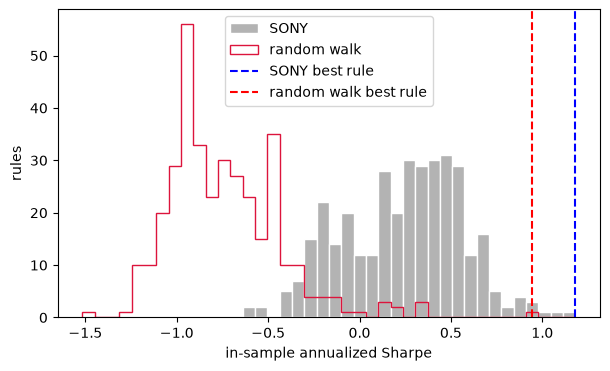

In [12]:
bins = np.linspace(
    min(in_sample.min(), rw_in_sample.min()),
    max(in_sample.max(), rw_in_sample.max()),
    41,
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(in_sample.dropna(), bins=bins, color='0.7', edgecolor='white', label='SONY')
ax.hist(rw_in_sample.dropna(), bins=bins, histtype='step', color='crimson', label='random walk')
ax.axvline(in_sample[best], color="blue", ls='--', label='SONY best rule')
ax.axvline(rw_in_sample[rw_best], color='red', ls='--', label='random walk best rule')
ax.set_xlabel('in-sample annualized Sharpe')
ax.set_ylabel('rules')
ax.legend()
plt.show()

In [13]:
rw_is_std = rw_in_sample.std(ddof=1)
rw_max_sharpe_est = rw_is_std * ((1-np.euler_gamma) * norm.ppf(1-1/len(rw_in_sample)) + np.euler_gamma * norm.ppf(1-1/(len(rw_in_sample)*np.e)))

sony_is_std = in_sample.std(ddof=1)
sony_is_mean = in_sample.mean()
# Mean added because sony is not necessarily zero mean.
sony_max_sharpe_est = sony_is_mean + sony_is_std * ((1-np.euler_gamma) * norm.ppf(1-1/len(in_sample)) + np.euler_gamma * norm.ppf(1-1/(len(in_sample)*np.e)))

print(f"Random walk in-sample Sharpe: {rw_in_sample[rw_best]:.2f}, expected max: {rw_max_sharpe_est:.2f}")
print(f"Sony in-sample Sharpe: {in_sample[best]:.2f}, expected max: {sony_max_sharpe_est:.2f}")

Random walk in-sample Sharpe: 0.94, expected max: 0.93
Sony in-sample Sharpe: 1.18, expected max: 1.24


## Discussion

The estimator of the maximum Sharpe ratio over a search admits a closed form approximation:

$$\mathbb{E}\Big[\max_N \widehat{SR}\Big]\approx\sigma_{SR}\Bigg[(1-\gamma)\Phi^{-1}\bigg(1-\frac{1}{N}\bigg) + \gamma\Phi^{-1}\bigg(1-\frac{1}{N}e^{-1}\bigg)\Bigg]$$

With $\gamma$ being the Euler-Mascheroni constant. The above approximation assumes N independent and Gaussian samples of Sharpe ratios. The prominance of that assumption is visible with the random walk case producing an in-sample Sharpe of 0.94 against the estimator's 0.93, while SONY is the opposite case. We fittingly observe the larger difference of 1.18 in-sample Sharpe against the estimator's 1.24. The nominal $N=500$ sample used for SONY is not appropriate if the best estimation is being seeked. The independent Gaussian Sharpe sample assumption is not generally valid in real world data as readily as it is in a random walk. Although we can't put a number on the effective $N$ of the SONY sample, we don't need a suitable ESS estimator to say it is strictly less than 500.

The experiment shows that sampling investment strategies produce a Sharpe ratio distribution with asymptotic properties that yield expectations regarding the upper bound of the maximum Sharpe. Therefore large Sharpe ratios in-sample are empirically and analytically shown to require statistical scrutiny.